## 1. Exploración del dataset
En esta sección cargaremos el dataset de tweets sobre Inteligencia Artificial, revisaremos su estructura general, tipos de datos, la presencia de valores faltantes y analizaremos el comportamiento de la variable objetivo (`polarity`).

Importación de Librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración del estilo gráfico predeterminado de Seaborn
sns.set(style="whitegrid")
%matplotlib inline

Carga del dataset de Tweets

In [2]:
# Carga el dataset de Tweets
df = pd.read_csv("https://raw.githubusercontent.com/Barlita03/TP-CienciasDeDatos/main/Consigna/ia_tweets.csv")
# df = pd.read_csv("https://drive.google.com/uc?id=1kYip8Kzlvh4WJ9rrC29R3eYVbOj8XCJQ")

# Muestra las primeras filas del dataset
df.head()

,ID,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_has_extended_profile,user_is_translator,user_protected,user_default_profile
0,0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,1,0,0,0
1,1,"@alvaropons Eso es imposible. Y sí, va a gener...",N,1,0,685,851,169490,128555,0,1,0,0,1
2,2,@alvaropons Lo disruptivo es que tras años de ...,NEU,1,0,685,851,169490,128555,0,1,0,0,1
3,3,"@alvaropons ¿""Prohibición del uso comercial de...",N,0,0,4877,538,6123,3156,0,1,0,0,0
4,4,@santoroydonoso Cómo se está estudiando prohib...,NEU,0,0,15936,2395,66945,68578,0,1,0,0,0


Información básica del dataset

In [3]:
# Información general (filas, columnas, tipos de datos y no nulos)
df.info()

# Verifica explícitamente la cantidad de valores faltantes por columna
print("\nValores faltantes por columna:")
print(df.isnull().sum())

# Revisa tipos de datos detallados
print("\nTipos de datos:")
print(df.dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 4038 entries, 0 to 4037
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   ID                         4038 non-null   int64
 1   text                       4038 non-null   str  
 2   polarity                   4038 non-null   str  
 3   favorite_count             4038 non-null   int64
 4   retweet_count              4038 non-null   int64
 5   user_followers_count       4038 non-null   int64
 6   user_friends_count         4038 non-null   int64
 7   user_favourites_count      4038 non-null   int64
 8   user_statuses_count        4038 non-null   int64
 9   user_verified              4038 non-null   int64
 10  user_has_extended_profile  4038 non-null   int64
 11  user_is_translator         4038 non-null   int64
 12  user_protected             4038 non-null   int64
 13  user_default_profile       4038 non-null   int64
dtypes: int64(12), str(2)
memory usage: 

*Observación: El dataset cuenta con 4038 registros y 14 columnas. El análisis de valores nulos (isnull().sum()) confirma que no existen valores faltantes en ninguna de las variables, por lo que no es necesario aplicar ninguna estrategia de limpieza de datos en esta etapa.*

Análisis de la columna "polarity"


Cantidad de tweets por clase:
polarity
NEU    2689
P       757
N       592
Name: count, dtype: int64

Porcentaje por clase:
polarity
NEU    66.59
P      18.75
N      14.66
Name: proportion, dtype: float64


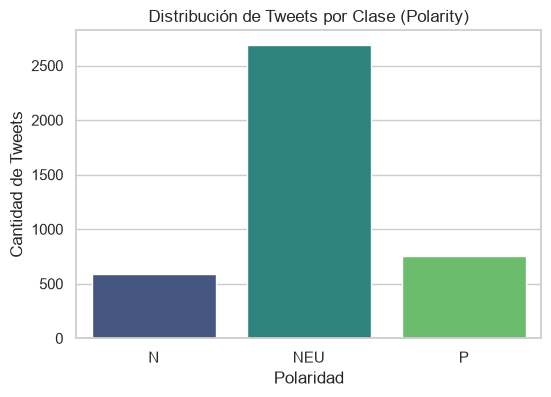

In [4]:
# Conteo de registros por clase en polarity
conteo_clases = df['polarity'].value_counts()
print("Cantidad de tweets por clase:")
print(conteo_clases)

# Porcentajes de participación por clase
porcentaje_clases = (df['polarity'].value_counts(normalize=True) * 100).round(2)
print("\nPorcentaje por clase:")
print(porcentaje_clases)

# Gráfico de barras (countplot) para visualizar la distribución de clases
plt.figure(figsize=(6, 4))
sns.countplot(x='polarity', hue='polarity', data=df, palette='viridis', legend=False)
plt.title('Distribución de Tweets por Clase (Polarity)')
plt.xlabel('Polaridad')
plt.ylabel('Cantidad de Tweets')
plt.show()

***Observación:***

**Cantidad de tweets por clase:**
  * **NEU (Neutral):** 2689 tweets (66.59%)
  * **P (Positivo):** 757 tweets (18.75%)
  * **N (Negativo):** 592 tweets (14.66%)

**¿El dataset está balanceado?**
  No, el dataset presenta un **marcado desbalance de clases**. La clase neutral (`NEU`) representa casi dos tercios del total de los datos (66.59%), mientras que las clases positiva y negativa minoritarias suman en conjunto poco más del 33%.

**¿Cómo puede afectar esto al entrenamiento de modelos?**
  El marcado desbalance de clases impacta de forma directa en el proceso de entrenamiento de los algoritmos de Machine Learning. Dado que la mayoría de los clasificadores buscan optimizar métricas globales de rendimiento (como el *accuracy*), un desproporcionado volumen de la clase mayoritaria (`NEU`) puede provocar que el modelo se sesgue o ignore los patrones de las clases minoritarias (`P` y `N`). Como se advierte ante la *Accuracy Paradox*, un modelo podría alcanzar una alta exactitud aparente simplemente prediciendo de manera sistemática la clase más frecuente, volviéndose inútil para la tarea de detección de sentimiento.

## 2. Análisis de las variables disponibles

Distribución de las métricas de interacción (`favorite_count` y `retweet_count`)

In [5]:
# Resumen estadístico de las métricas de interacción (con percentiles altos para ver la cola)
display(df[['favorite_count', 'retweet_count']].describe(percentiles=[.25, .5, .75, .9, .99]))

# Porcentaje de tweets sin ninguna interacción
print(f"Porcentaje de favoritos en cero: {(df['favorite_count'] == 0).mean() * 100:.2f}%")
print(f"Porcentaje de retweets en cero: {(df['retweet_count'] == 0).mean() * 100:.2f}%")

,favorite_count,retweet_count
count,4038.000000,4038.000000
mean,3.815998,0.874938
std,45.041517,9.645228
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,1.000000,0.000000
90%,5.000000,1.000000
99%,41.000000,14.630000
max,2243.000000,502.000000


Porcentaje de favoritos en cero: 53.15%
Porcentaje de retweets en cero: 84.74%


favorite_count (solo > 0): n=1892 (46.85% del total), mediana=2.0, percentil 90=10.0, máximo=2243
retweet_count (solo > 0): n=616 (15.26% del total), mediana=2.0, percentil 90=8.5, máximo=502


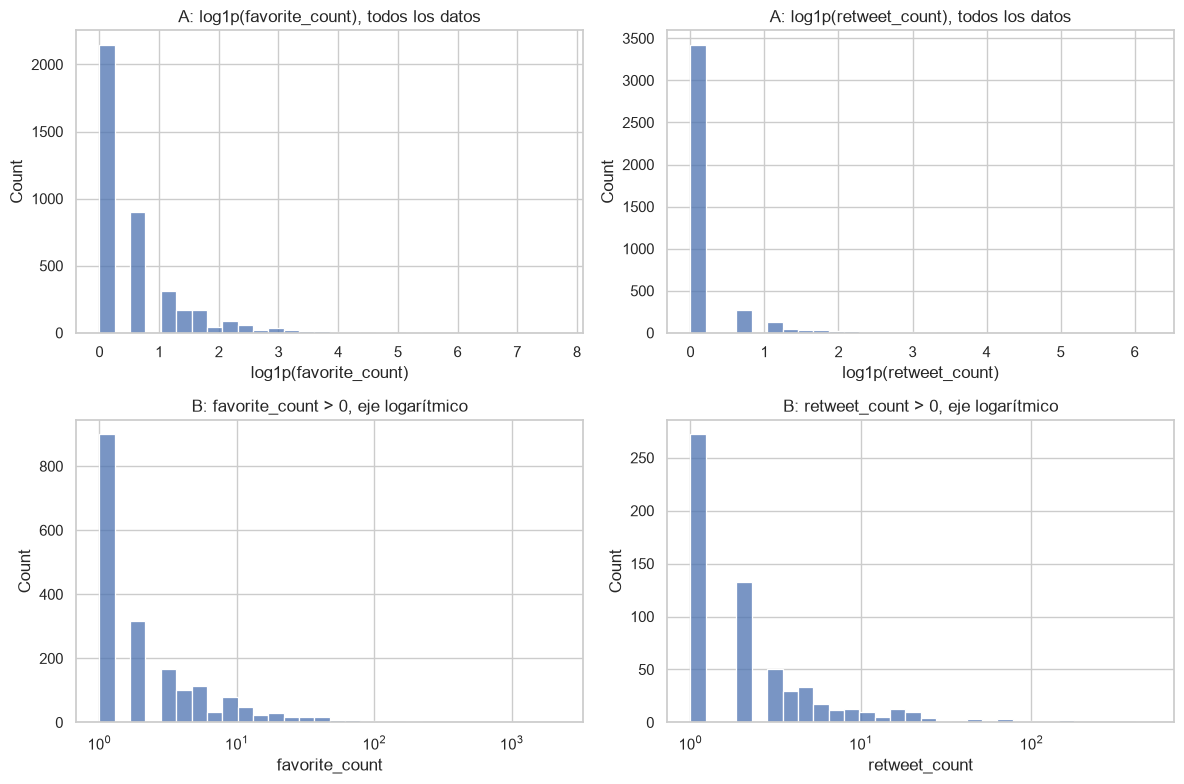

In [6]:
cols = ['favorite_count', 'retweet_count']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for i, col in enumerate(cols):
    # Tweets con al menos una interacción (> 0)
    con_interaccion = df[df[col] > 0][col]
    print(f"{col} (solo > 0): n={len(con_interaccion)} ({len(con_interaccion) / len(df) * 100:.2f}% del total), "
          f"mediana={con_interaccion.median()}, percentil 90={con_interaccion.quantile(.9)}, máximo={con_interaccion.max()}")

    # Opción A: todos los datos, transformados con log1p = log(1 + x), que admite el 0
    sns.histplot(np.log1p(df[col]), bins=30, ax=axes[0, i])
    axes[0, i].set_title(f'A: log1p({col}), todos los datos')
    axes[0, i].set_xlabel(f'log1p({col})')

    # Opción B: solo los tweets con interacción, con eje X logarítmico
    sns.histplot(con_interaccion, bins=30, log_scale=True, ax=axes[1, i])
    axes[1, i].set_title(f'B: {col} > 0, eje logarítmico')

plt.tight_layout()
plt.show()

***Observación:***

* **Las dos tienen la misma forma.** Al menos 9 de cada 10 tweets tienen 5 favoritos o menos y 1 retweet o menos, pero hay valores muy lejanos: el máximo es 2243 favoritos y 502 retweets, unas 55 y 34 veces el percentil 99 respectivamente.
* **Muchos ceros.** El 53,15% de los tweets no tiene favoritos y el 84,74% no tiene retweets. La mediana de ambas es 0.
* **No es una distribución gaussiana.** Es asimétrica a la derecha, con una cola larga. La media (3,82 favoritos y 0,87 retweets) queda muy por encima de la mediana porque la arrastran pocos tweets, así que no representa a un tweet típico. La mediana y los percentiles resumen mejor estos datos.
* **Cómo graficarla.** Un histograma común no sirve, porque casi todos los datos caen en las primeras barras (ver *Alternativas probadas*). Con `log1p` (A) se ve todo el dataset, ceros incluidos, y muestra la proporción real de tweets sin interacción, pero la barra del 0 domina el gráfico. Con el filtro `> 0` y el eje logarítmico (B) se aprecia cómo se reparten los tweets que sí tuvieron interacción (la mayoría entre 1 y 2, con una caída gradual hasta los extremos), pero no se ven los ceros.
* **Decisión.** Cada gráfico responde una pregunta distinta, así que se usan los dos: A y los porcentajes de ceros para la proporción sin interacción, y B para la forma de la distribución entre quienes sí interactuaron.

#### Alternativas probadas

favorite_count: 99.55% de los datos cae en el primer bin
retweet_count: 99.11% de los datos cae en el primer bin


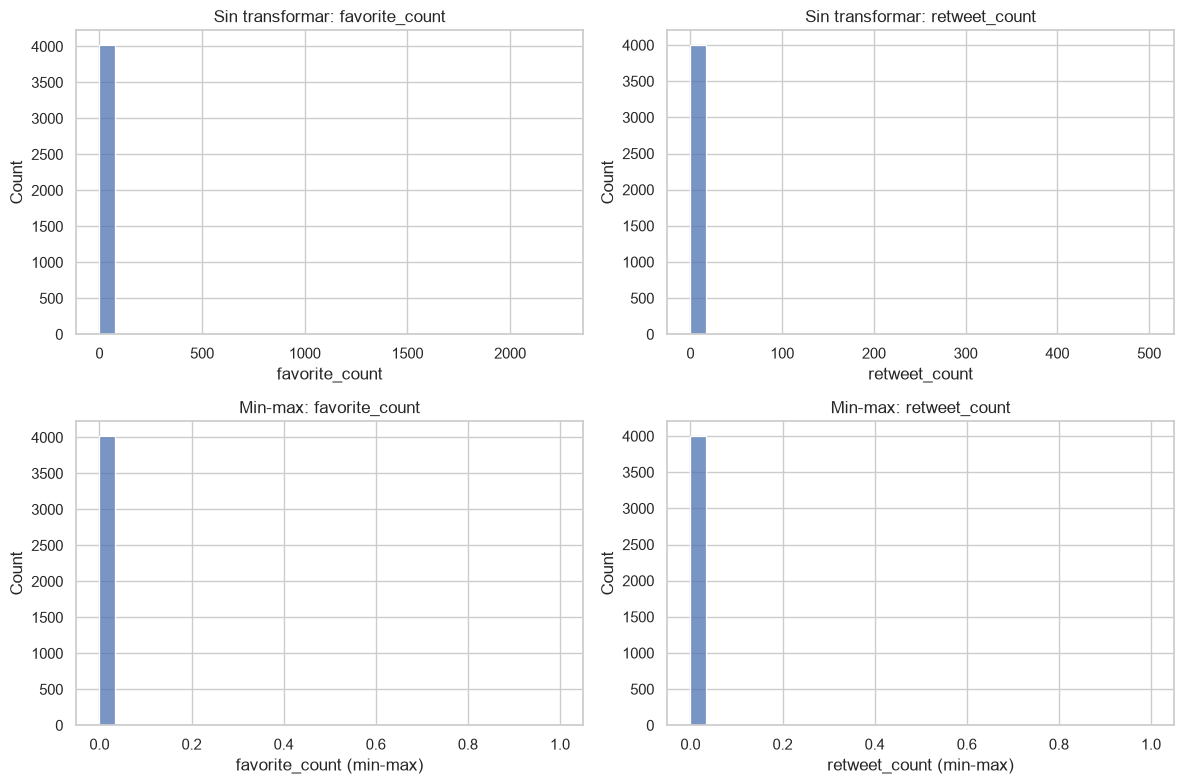

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for i, col in enumerate(cols):
    # Alternativa 1: histograma de los datos sin transformar
    sns.histplot(df[col], bins=30, ax=axes[0, i])
    axes[0, i].set_title(f'Sin transformar: {col}')

    # Alternativa 2: normalización min-max, (x - min) / (max - min)
    minmax = (df[col] - df[col].min()) / (df[col].max() - df[col].min())
    sns.histplot(minmax, bins=30, ax=axes[1, i])
    axes[1, i].set_title(f'Min-max: {col}')
    axes[1, i].set_xlabel(f'{col} (min-max)')

    # Porcentaje de datos en el primer bin (de ancho max / 30)
    primer_bin = (df[col] <= df[col].max() / 30).mean()
    print(f"{col}: {primer_bin * 100:.2f}% de los datos cae en el primer bin")

plt.tight_layout()
plt.show()

***Observación:***

* **Sin transformar:** más del 99% de los datos cae en el primer bin en ambas variables, así que el histograma muestra una sola barra y la cola es imperceptible.
* **Min-max:** solo cambia la escala del eje X a [0, 1], la forma del histograma es idéntica. No resuelve el problema, y como depende del máximo, un solo valor extremo (2243 o 502) alcanza para dejar al resto pegado al 0.
* **Decisión:** ambas se descartan. Lo que sí descomprime la cola es una transformación logarítmica, como en A y B.

¿Los tweets positivos reciben más interacción que los negativos?

In [8]:
orden = ['P', 'NEU', 'N']

for col in cols:
    por_clase = df.groupby('polarity')[col]
    con_interaccion = df[df[col] > 0].groupby('polarity')[col]

    # Cuántos tweets de cada clase tienen al menos una interacción
    resumen = pd.DataFrame({
        'tweets': por_clase.size(),
        'tweets > 0': con_interaccion.size(),
        '% > 0': (por_clase.apply(lambda s: (s > 0).mean()) * 100).round(2),
    })

    # Cuánta interacción reciben los que sí tienen
    percentiles = con_interaccion.quantile([.5, .75, .9, .99]).unstack()
    percentiles.columns = ['p50 (> 0)', 'p75 (> 0)', 'p90 (> 0)', 'p99 (> 0)']

    print(col)
    display(resumen.join(percentiles).loc[orden])

favorite_count


,tweets,tweets > 0,% > 0,p50 (> 0),p75 (> 0),p90 (> 0),p99 (> 0)
polarity,,,,,,,
P,757,346,45.71,1.0,3.0,9.5,52.55
NEU,2689,1287,47.86,2.0,4.0,10.0,68.56
N,592,259,43.75,2.0,4.0,9.2,111.24


retweet_count


,tweets,tweets > 0,% > 0,p50 (> 0),p75 (> 0),p90 (> 0),p99 (> 0)
polarity,,,,,,,
P,757,101,13.34,2.0,4.00,7.0,50.00
NEU,2689,431,16.03,2.0,4.00,9.0,73.50
N,592,84,14.19,1.0,3.25,7.0,67.74


***Observación:***

* **Proporción de tweets con interacción.** El porcentaje de tweets con al menos un favorito es similar en las tres clases (P: 45,71%; NEU: 47,86%; N: 43,75%), al igual que el de tweets con al menos un retweet (P: 13,34%; NEU: 16,03%; N: 14,19%). Se compara en términos relativos porque las clases tienen tamaños distintos.
* **Magnitud de la interacción.** Entre los tweets con interacción, las medianas se ubican entre 1 y 2, y los percentiles 75 y 90 son muy próximos en las tres clases. El percentil 99 no se usa para comparar porque depende de muy pocos tweets (en la clase N, apenas 2 o 3).
* **Ausencia de una clase dominante.** El sentido de las diferencias se invierte según el indicador: P supera a N en la proporción de tweets con favoritos y en la mediana de retweets, mientras que N supera a P en la mediana de favoritos y en la proporción de tweets con retweets. La clase neutral, tomada como referencia, se ubica próxima a ambas.
* **Conclusión.** Los datos no muestran evidencia de que los tweets positivos reciban más interacción que los negativos: las diferencias entre clases son reducidas y no mantienen una dirección consistente.
* **Implicancia para el modelado.** Es de esperar que `favorite_count` y `retweet_count`, consideradas de forma aislada, aporten poca información para distinguir el sentimiento. Esta hipótesis se evaluará en la etapa de modelado.

#### Alternativas probadas

In [9]:
for col in cols:
    por_clase = df.groupby('polarity')[col]

    # Alternativa: media y máximo por clase, y media recalculada sin el tweet con el valor máximo
    alternativa = pd.DataFrame({
        'media': por_clase.mean().round(2),
        'mediana': por_clase.median(),
        'máximo': por_clase.max(),
        'media sin el máximo': por_clase.apply(lambda s: s.drop(s.idxmax()).mean()).round(2),
    })

    print(col)
    display(alternativa.loc[orden])

favorite_count


,media,mediana,máximo,media sin el máximo
polarity,,,,
P,5.02,0.0,2243,2.06
NEU,3.66,0.0,1061,3.27
N,2.97,0.0,350,2.38


retweet_count


,media,mediana,máximo,media sin el máximo
polarity,,,,
P,1.20,0.0,502,0.54
NEU,0.83,0.0,170,0.76
N,0.68,0.0,86,0.54


***Observación:***

* **Media:** según la media, los tweets positivos recibirían más interacción en ambas métricas (5,02 favoritos frente a 2,97 en N). Sin embargo, al excluir únicamente el tweet con más favoritos de cada clase, la media de P desciende a 2,06 y queda por debajo de la de N (2,38); en retweets, ambas se igualan en 0,54. La conclusión depende de un único tweet.
* **Máximo:** corresponde a un solo tweet y tiende a crecer con el tamaño del grupo, por lo que no permite comparar clases de tamaños distintos.
* **Decisión:** ambas se descartan, porque no representan el comportamiento de cada clase.

#### Relación con el tamaño de la cuenta

Como complemento, se analiza si la interacción depende de la cuenta que publica el tweet.

In [10]:
# Correlación entre la interacción y los seguidores de la cuenta.
# Se calcula sobre log1p, como en los gráficos de la distribución, para que los valores extremos no dominen el cálculo
display(np.log1p(df[cols + ['user_followers_count']]).corr().round(2))

,favorite_count,retweet_count,user_followers_count
favorite_count,1.00,0.75,0.41
retweet_count,0.75,1.00,0.33
user_followers_count,0.41,0.33,1.00


In [11]:
# Proporción de clases y mediana de seguidores según el nivel de interacción.
# Se usan varios cortes porque cualquier umbral para definir un tweet "viral" es arbitrario (J-06)
for col in cols:
    p95, p99 = df[col].quantile([.95, .99])
    grupos = {
        'todos': df,
        '= 0': df[df[col] == 0],
        '> 0': df[df[col] > 0],
        f'top 5% (>= {p95:.0f})': df[df[col] >= p95],
        f'top 1% (> {p99:.1f})': df[df[col] > p99],
    }
    filas = []
    for nombre, grupo in grupos.items():
        proporcion = (grupo['polarity'].value_counts(normalize=True) * 100).round(1)
        filas.append(pd.Series({
            'tweets': len(grupo),
            **proporcion.to_dict(),
            'mediana seguidores': grupo['user_followers_count'].median(),
        }, name=nombre))
    resumen = pd.DataFrame(filas)[['tweets'] + orden + ['mediana seguidores']]

    print(col)
    display(resumen.astype({'tweets': int}))

favorite_count


,tweets,P,NEU,N,mediana seguidores
todos,4038,18.7,66.6,14.7,622.0
= 0,2146,19.2,65.3,15.5,274.0
> 0,1892,18.3,68.0,13.7,1651.5
top 5% (>= 10),204,17.2,70.1,12.7,8084.0
top 1% (> 41.0),40,15.0,67.5,17.5,18932.0


retweet_count


,tweets,P,NEU,N,mediana seguidores
todos,4038,18.7,66.6,14.7,622.0
= 0,3422,19.2,66.0,14.8,473.0
> 0,616,16.4,70.0,13.6,3689.0
top 5% (>= 3),211,15.2,70.6,14.2,8482.0
top 1% (> 14.6),41,19.5,65.9,14.6,25586.0


***Observación:***

* **Correlación con los seguidores.** En escala `log1p`, la correlación con los seguidores es positiva y moderada: 0,41 en favoritos y 0,33 en retweets. Sobre los valores originales no se aprecia, porque unos pocos tweets extremos dominan el cálculo (ver *Alternativas probadas*). Al ser moderada, hay excepciones: el segundo tweet con más favoritos (1061) es de una cuenta con 530 seguidores.
* **Sentimiento según el nivel de interacción.** A medida que aumenta la interacción, la mediana de seguidores crece de forma marcada: en favoritos pasa de 274 en los tweets sin favoritos a 18.932 en el 1% con más favoritos, y en retweets, de 473 a 25.586. En cambio, la proporción de clases se mantiene cerca de la del dataset completo en todos los cortes (a no más de 4 puntos) y sin una dirección consistente.
* **Conclusión.** La interacción depende más de quién publica el tweet que de su sentimiento. Esto refuerza la respuesta anterior y explica de dónde provienen los valores extremos que se analizan a continuación.

#### Alternativas probadas

In [12]:
# Correlación sobre los valores originales, sin transformar
display(df[cols + ['user_followers_count']].corr().round(2))

# Cuánto la mueve un solo tweet: favoritos y retweets sin el tweet con más favoritos
sin_maximo = df.drop(index=df['favorite_count'].idxmax())
print("Correlación entre favoritos y retweets sin el tweet con más favoritos: "
      f"{sin_maximo['favorite_count'].corr(sin_maximo['retweet_count']):.2f}")

# La cuenta con más seguidores y la interacción de su tweet
display(df.nlargest(1, 'user_followers_count')[['user_followers_count', 'favorite_count', 'retweet_count']])

,favorite_count,retweet_count,user_followers_count
favorite_count,1.00,0.94,0.04
retweet_count,0.94,1.00,0.05
user_followers_count,0.04,0.05,1.00


Correlación entre favoritos y retweets sin el tweet con más favoritos: 0.84


,user_followers_count,favorite_count,retweet_count
1577,10165395,35,8


***Observación:***

* **Correlación sobre los valores originales:** con los seguidores es casi nula (0,04 en favoritos y 0,05 en retweets), y entre favoritos y retweets es 0,94. Estos valores dependen de unos pocos tweets extremos: quitar solo el tweet con más favoritos baja la correlación entre favoritos y retweets de 0,94 a 0,84, y la cuenta con más seguidores (más de 10 millones) tiene apenas 35 favoritos.
* **Decisión:** se descarta, porque refleja a unos pocos tweets extremos y no al conjunto. Sobre `log1p` cada tweet pesa de forma más pareja.

¿Se observan outliers?

In [13]:
# Valores imposibles: ninguna métrica de interacción puede ser negativa
print(f"Mínimos: {df[cols].min().to_dict()}")

# Qué tan lejos están los valores extremos del resto: el máximo en relación con el percentil 99
for col in cols:
    p99 = df[col].quantile(.99)
    print(f"{col}: máximo={df[col].max()}, percentil 99={p99:.2f}, máximo / p99={df[col].max() / p99:.1f}")

# Tweets con más interacción, con datos de la cuenta para evaluar si los valores son creíbles
top_favoritos = df.nlargest(5, 'favorite_count')
top_retweets = df.nlargest(5, 'retweet_count')
print(f"¿Son los mismos 5 tweets en ambas métricas? {set(top_favoritos.index) == set(top_retweets.index)}")
print(f"Mediana de seguidores del dataset: {df['user_followers_count'].median()}")
display(top_favoritos[['favorite_count', 'retweet_count', 'polarity', 'user_followers_count', 'user_verified', 'text']])

Mínimos: {'favorite_count': 0, 'retweet_count': 0}
favorite_count: máximo=2243, percentil 99=41.00, máximo / p99=54.7
retweet_count: máximo=502, percentil 99=14.63, máximo / p99=34.3
¿Son los mismos 5 tweets en ambas métricas? True
Mediana de seguidores del dataset: 622.0


,favorite_count,retweet_count,polarity,user_followers_count,user_verified,text
1292,2243,502,P,146283,1,🔴 OPEN ASSISTANT YA ESTÁ AQUÍ!\n\n¿Recordáis e...
3921,1061,122,NEU,530,0,yo solo uso ChatGPT para esto https://t.co/YC3...
993,1033,111,NEU,283630,1,"Programar no está muriendo. En cambio, las her..."
1886,495,146,NEU,19737,0,El problema de la inteligencia artificial es q...
2188,396,170,NEU,72127,0,"✅ Guía de #ChatGPT: cómo funciona, ventajas y ..."


***Observación:***

* **Sin valores imposibles.** El mínimo de ambas métricas es 0, por lo que no se registran valores negativos atribuibles a errores de carga.
* **Valores extremos.** Se observan valores muy alejados del resto: el máximo es de 2243 favoritos y 502 retweets, aproximadamente 55 y 34 veces el percentil 99, respectivamente.
* **Plausibilidad.** Los cinco tweets con más favoritos son también los cinco con más retweets, lo cual es coherente con una difusión real y no con un error en una columna aislada. Dos de ellos provienen de cuentas verificadas con más de 140.000 seguidores, frente a una mediana de 622 en el dataset.
* **Criterio adoptado.** Las reglas automáticas de detección no se ajustan a esta distribución (ver *Alternativas probadas*), y un corte por percentil requeriría fijar un umbral arbitrario. Por ello, la pregunta se responde de forma descriptiva: se cuantifica la distancia de los extremos respecto del resto y se verifica que correspondan a valores reales. Este enfoque no produce una lista exacta de outliers, que no es necesaria para responder si se observan.
* **Conclusión.** Se observan outliers en ambas métricas. Los casos revisados corresponden a tweets reales con alta difusión y forman parte de la cola larga de la distribución, por lo que no constituyen errores a corregir.
* **Tratamiento.** La forma de tratarlos se decidirá en la etapa de modelado, ya que depende del modelo utilizado.

#### Alternativas probadas

In [14]:
for col in cols:
    # Alternativa 1: regla del IQR, Q3 + 1,5 × (Q3 − Q1)
    q1, q3 = df[col].quantile([.25, .75])
    limite = q3 + 1.5 * (q3 - q1)
    print(f"{col} | IQR: Q1={q1}, Q3={q3}, límite={limite}, "
          f"outliers={(df[col] > limite).sum()} ({(df[col] > limite).mean() * 100:.2f}%)")

    # Alternativa 2: la misma regla sobre log1p, con el límite vuelto a la escala original (expm1)
    log_q1, log_q3 = np.log1p(df[col]).quantile([.25, .75])
    limite_log = np.expm1(log_q3 + 1.5 * (log_q3 - log_q1))
    print(f"{col} | IQR sobre log1p: límite={limite_log:.2f}, "
          f"outliers={(df[col] > limite_log).sum()} ({(df[col] > limite_log).mean() * 100:.2f}%)")

    # Alternativa 3: puntaje z, más de 3 desvíos estándar por encima de la media
    limite_z = df[col].mean() + 3 * df[col].std()
    print(f"{col} | puntaje z: límite={limite_z:.2f}, outliers={(df[col] > limite_z).sum()}")

    # Sensibilidad del desvío a un solo tweet
    print(f"{col} | desvío con todos los tweets={df[col].std():.2f}, "
          f"sin el máximo={df[col].drop(df[col].idxmax()).std():.2f}\n")

favorite_count | IQR: Q1=0.0, Q3=1.0, límite=2.5, outliers=678 (16.79%)
favorite_count | IQR sobre log1p: límite=4.66, outliers=410 (10.15%)
favorite_count | puntaje z: límite=138.94, outliers=11
favorite_count | desvío con todos los tweets=45.04, sin el máximo=28.05

retweet_count | IQR: Q1=0.0, Q3=0.0, límite=0.0, outliers=616 (15.26%)
retweet_count | IQR sobre log1p: límite=0.00, outliers=616 (15.26%)
retweet_count | puntaje z: límite=29.81, outliers=14
retweet_count | desvío con todos los tweets=9.65, sin el máximo=5.55



***Observación:***

* **Regla del IQR:** en `retweet_count`, más del 75% de los valores es 0, por lo que Q1 = Q3 = 0 y el límite queda en 0: cualquier tweet con al menos un retweet se considera outlier (15,26%). En `favorite_count` marca a todo tweet con 3 o más favoritos (16,79%). Aplicada sobre `log1p` tampoco resuelve el problema: el límite de retweets sigue en 0 y en favoritos marca el 10,15% de los tweets.
* **Puntaje z:** marca 11 tweets en favoritos y 14 en retweets, pero supone una distribución aproximadamente normal y su límite depende de la media y el desvío, que se calculan con los mismos valores extremos que busca detectar. Excluir un solo tweet reduce el desvío de favoritos de 45,04 a 28,05.
* **Decisión:** ambas se descartan, porque no ofrecen un criterio confiable para esta distribución.

## 3. Ingeniería de features

En esta sección se construyen nuevas features a partir del texto de cada tweet y se analiza si su distribución cambia según la clase. Que una feature muestre diferencias entre clases es un primer indicio de que puede ayudar al modelo; su aporte real se evalúa en la etapa de modelado.

Longitud del tweet

Tweets que quedan vacíos al quitar URLs y menciones: 52


,p25,mediana,p75
polarity,,,
P,105.0,182.0,245.00
NEU,71.0,163.0,242.00
N,96.0,171.0,248.25


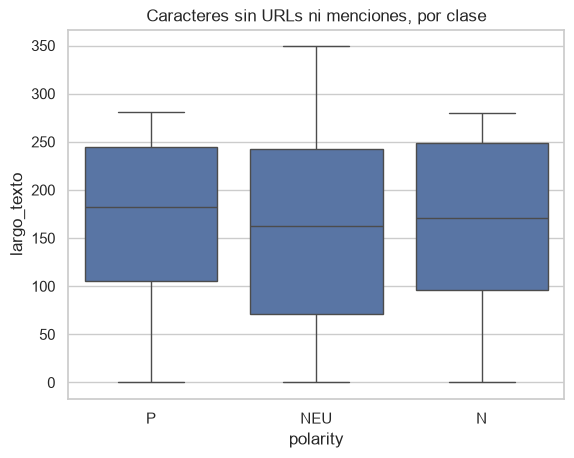

In [15]:
# Texto sin URLs ni menciones: deja solo lo que escribió la persona
texto_sin_urls_menciones = (df['text']
                            .str.replace(r'https?://\S+', '', regex=True)
                            .str.replace(r'@\w+', '', regex=True)
                            .str.strip())

# Feature: cantidad de caracteres del texto sin URLs ni menciones
df['largo_texto'] = texto_sin_urls_menciones.str.len()

print(f"Tweets que quedan vacíos al quitar URLs y menciones: {(df['largo_texto'] == 0).sum()}")

# Percentiles por clase
display(df.groupby('polarity')['largo_texto'].quantile([.25, .5, .75]).unstack().set_axis(['p25', 'mediana', 'p75'], axis=1).loc[orden])

sns.boxplot(data=df, x='polarity', y='largo_texto', order=orden)
plt.title('Caracteres sin URLs ni menciones, por clase')
plt.show()

***Observación:***

* **Cómo se construye.** Se quitan del texto las URLs y las menciones y se cuentan los caracteres restantes, para medir solo lo que escribió la persona: un link ocupa unos 23 caracteres y, en las respuestas, las menciones del inicio pueden ser muchas, sin que nada de eso sea texto propio (ver *Alternativas probadas*). 52 tweets quedan con largo 0 porque solo contenían links o menciones; es un valor válido y se mantiene.
* **P y N.** Tienen una longitud muy parecida: medianas de 182 y 171 caracteres y percentiles 75 casi iguales (245 y 248). La longitud no ayuda a distinguir entre positivos y negativos.
* **NEU.** Tiene más tweets cortos: el 25% más corto de los neutrales tiene hasta 71 caracteres, frente a 105 en P y 96 en N. La parte alta de la distribución es similar en las tres clases.
* **Conclusión.** Se adopta `largo_texto` como feature. Puede aportar para distinguir a los neutrales de las otras dos clases, pero no para separar positivos de negativos. Su aporte real se evalúa en el modelado.

#### Alternativas probadas

Caracteres del texto original


,p25,mediana,p75
polarity,,,
P,118.0,192.0,261.00
NEU,95.0,184.0,264.00
N,118.0,193.0,266.25


Palabras sin URLs ni menciones


,p25,mediana,p75
polarity,,,
P,15.0,28.0,38.00
NEU,12.0,27.0,39.00
N,16.0,29.0,40.25


Tweets con más de 280 caracteres: 464 (51% empieza con una mención)
Tweets con más de 280 caracteres sin URLs ni menciones: 3


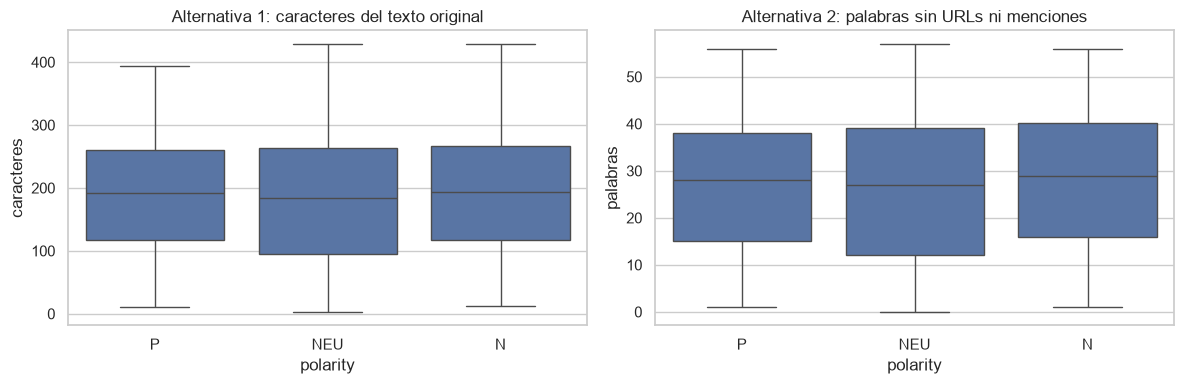

In [16]:
# Alternativa 1: caracteres del texto original, sin quitar URLs ni menciones
largo_original = df['text'].str.len()

# Alternativa 2: cantidad de palabras del texto sin URLs ni menciones
palabras = texto_sin_urls_menciones.str.split().str.len()

for nombre, serie in [('Caracteres del texto original', largo_original),
                      ('Palabras sin URLs ni menciones', palabras)]:
    print(nombre)
    display(serie.groupby(df['polarity']).quantile([.25, .5, .75]).unstack().set_axis(['p25', 'mediana', 'p75'], axis=1).loc[orden])

# Cuánto inflan las URLs y las menciones: tweets que superan el límite de 280 caracteres de Twitter
mas_de_280 = df.loc[largo_original > 280, 'text']
print(f"Tweets con más de 280 caracteres: {len(mas_de_280)} "
      f"({mas_de_280.str.startswith('@').mean() * 100:.0f}% empieza con una mención)")
print(f"Tweets con más de 280 caracteres sin URLs ni menciones: {(df['largo_texto'] > 280).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df['polarity'], y=largo_original, order=orden, ax=axes[0])
axes[0].set_title('Alternativa 1: caracteres del texto original')
axes[0].set_ylabel('caracteres')
sns.boxplot(x=df['polarity'], y=palabras, order=orden, ax=axes[1])
axes[1].set_title('Alternativa 2: palabras sin URLs ni menciones')
axes[1].set_ylabel('palabras')
plt.tight_layout()
plt.show()

***Observación:***

* **Caracteres del texto original:** las medianas son 192 (P), 184 (NEU) y 193 (N). La diferencia de NEU en los tweets cortos es menor que con la feature elegida: su percentil 25 es un 19% más bajo que el de P (95 frente a 118), contra un 32% con `largo_texto` (71 frente a 105). Además, la medida se infla con contenido que no es texto propio: 464 tweets superan el límite de 280 caracteres de Twitter y el 51% de ellos empieza con una mención; sin URLs ni menciones, solo 3 quedan por encima de ese límite.
* **Palabras sin URLs ni menciones:** muestra el mismo patrón, con NEU con más tweets cortos (percentil 25 de 12 palabras, frente a 15 en P y 16 en N), pero la diferencia es menos marcada: un 20% más bajo que P, contra un 32% en caracteres.
* **Decisión:** ambas se descartan. La primera mide en parte links y menciones, y la segunda no agrega información respecto de contar caracteres y separa menos a los neutrales.